<a href="https://colab.research.google.com/github/MauricioTurdo/Aprendizaje_Automatico/blob/main/Clase6/Practico_Clase_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje Automático — Semana 6
## Clasificación del nivel de rendimiento físico: Regresión Logística vs. Árbol de Decisión




## 1. Importación de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

sns.set_theme(style='whitegrid', font_scale=1.05)
ORDER = ['A', 'B', 'C', 'D']

## 2. Carga del dataset

In [ ]:
df = pd.read_csv('bodyPerformance.csv')
df.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


## 3. Análisis Exploratorio de Datos (EDA)

### 3.1 Información general del dataset

In [ ]:
print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")
print()
df.info()

Registros: 13393 | Variables: 12

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


In [ ]:
print("Descripción estadística de variables numéricas:")
df.describe().round(2)

Descripción estadística de variables numéricas:


,age,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm
count,13393.00,13393.00,13393.00,13393.00,13393.00,13393.00,13393.00,13393.00,13393.00,13393.00
mean,36.78,168.56,67.45,23.24,78.80,130.23,36.96,15.21,39.77,190.13
std,13.63,8.43,11.95,7.26,10.74,14.71,10.62,8.46,14.28,39.87
min,21.00,125.00,26.30,3.00,0.00,0.00,0.00,-25.00,0.00,0.00
25%,25.00,162.40,58.20,18.00,71.00,120.00,27.50,10.90,30.00,162.00
50%,32.00,169.20,67.40,22.80,79.00,130.00,37.90,16.20,41.00,193.00
75%,48.00,174.80,75.30,28.00,86.00,141.00,45.20,20.70,50.00,221.00
max,64.00,193.80,138.10,78.40,156.20,201.00,70.50,213.00,80.00,303.00


El dataset no tiene valores nulos. Pero mirando los mínimos y máximos aparecen **valores imposibles**: presión diastólica y sistólica de 0, fuerza de agarre de 0 y una flexibilidad máxima de 213 cm.


Distribución de class:
  Clase A:  3348 personas (25.0%)
  Clase B:  3347 personas (25.0%)
  Clase C:  3349 personas (25.0%)
  Clase D:  3349 personas (25.0%)


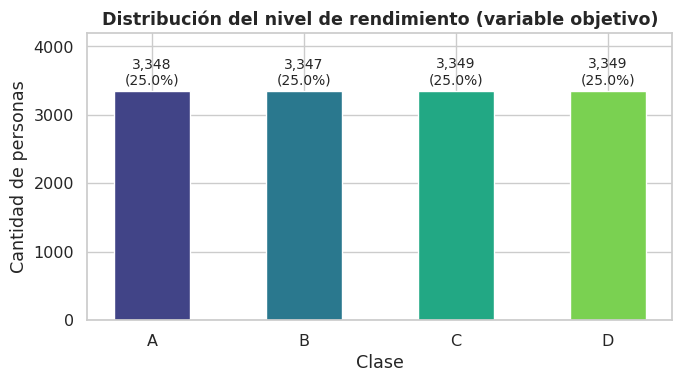

In [ ]:
conteo = df['class'].value_counts().reindex(ORDER)
pct = df['class'].value_counts(normalize=True).reindex(ORDER) * 100

print("Distribución de class:")
for cat, c, p in zip(ORDER, conteo, pct):
    print(f"  Clase {cat}: {c:5d} personas ({p:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(ORDER, conteo.values, color=sns.color_palette('viridis', 4), width=0.5, edgecolor='white')
for bar, val, p in zip(bars, conteo.values, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val:,}\n({p:.1f}%)', ha='center', va='bottom', fontsize=10)
ax.set_title('Distribución del nivel de rendimiento (variable objetivo)', fontweight='bold')
ax.set_xlabel('Clase')
ax.set_ylabel('Cantidad de personas')
ax.set_ylim(0, 4200)
plt.tight_layout()
plt.show()

Las 4 clases tienen aproximadamente **25 % de los casos cada una**: el dataset está balanceado. Por eso podemos usar el *accuracy* como métrica principal, y mirar *precision*, *recall* y *F1* para ver cómo le va a cada clase.



### Relación entre Variables y la clase

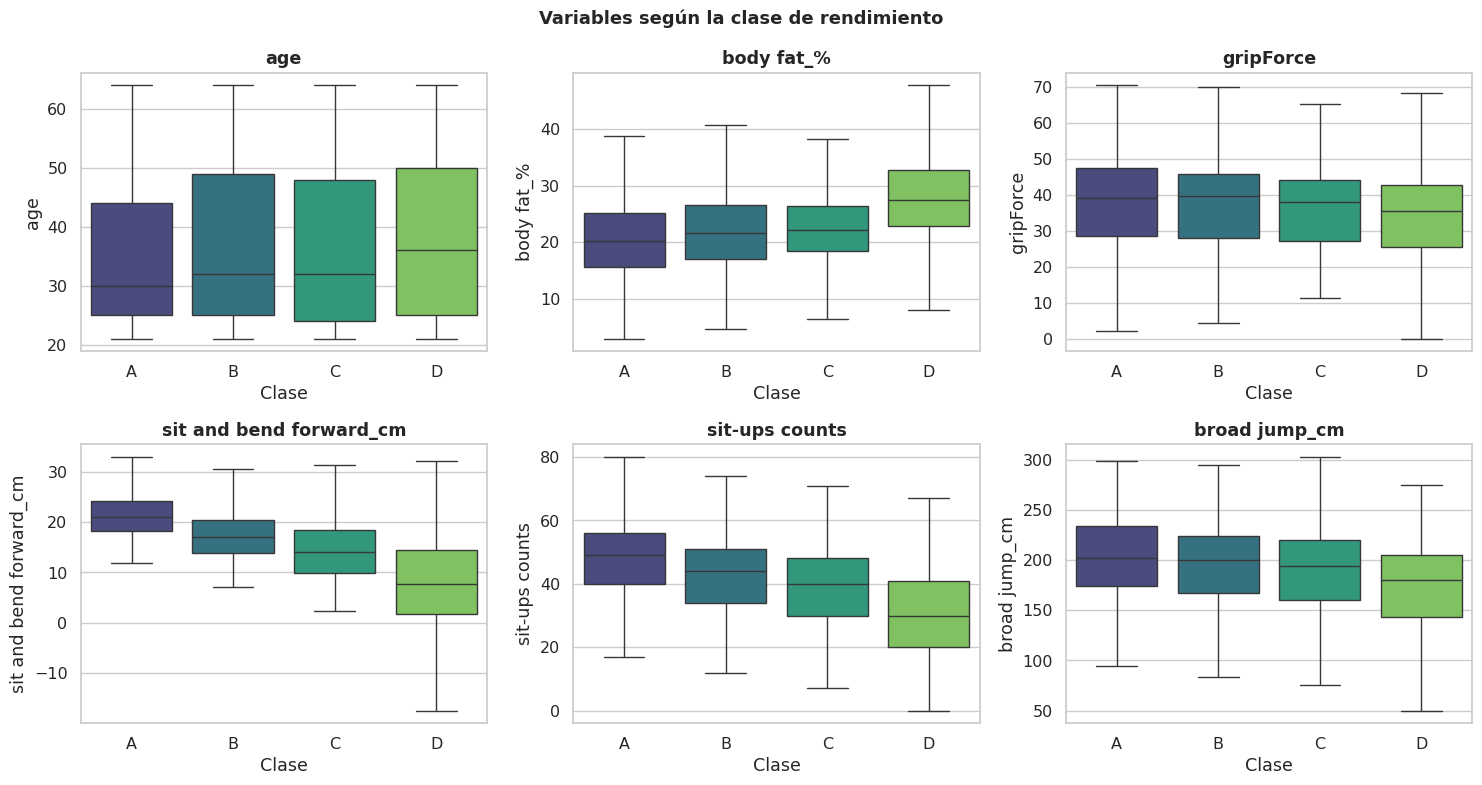

In [ ]:
variables = ['age', 'body fat_%', 'gripForce',
             'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), variables):
    sns.boxplot(data=df, x='class', y=col, order=ORDER, palette='viridis',
                showfliers=False, ax=ax)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Clase')
fig.suptitle('Variables según la clase de rendimiento', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Limpieza de datos
Eliminamos solo los registros con valores **imposibles**
- presión diastólica ≤ 40 o sistólica ≤ 60
- fuerza de agarre = 0
- flexibilidad ≥ 100 cm

In [ ]:
df_clean = df[
    (df['diastolic'] > 40) &
    (df['systolic'] > 60) &
    (df['gripForce'] > 0) &
    (df['sit and bend forward_cm'] < 100)
].copy()

print(f"Registros originales: {len(df)}")
print(f"Registros limpios:    {len(df_clean)}")
print(f"Registros eliminados: {len(df) - len(df_clean)}")

Registros originales: 13393
Registros limpios:    13380
Registros eliminados: 13


Se eliminaron muy pocos registros, así que no cambia el balance de las clases.

## Preprocesamiento

### Separar variables predictoras (X) y variable objetivo (y)
La variable **gender** es categórica, así que la convertimos en números con **one-hot encoding**. Usamos drop_first=True: queda una sola columna, gender_M (1 = hombre, 0 = mujer).

In [ ]:
X = df_clean.drop(columns='class')
y = df_clean['class']

X = pd.get_dummies(X, columns=['gender'], drop_first=True, dtype=int)

print(f"Variables predictoras: {X.shape[1]}")
print(list(X.columns))

Variables predictoras: 11
['age', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'gender_M']


### Codificación de la variable objetivo
Pasamos las clases de texto a números con LabelEncoder: A = 0, B = 1, C = 2, D = 3.

### División entrenamiento / prueba
80 % para entrenar y 20 % para evaluar. Con stratify las 4 clases mantienen la misma proporción en los dos conjuntos.

In [ ]:
le = LabelEncoder()
y_enc = le.fit_transform(y)
print("Clases:", list(le.classes_), "→", list(le.transform(le.classes_)))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42, stratify=y_enc)

print(f"\nTamaño train: {X_train.shape[0]} | test: {X_test.shape[0]}")

Clases: ['A', 'B', 'C', 'D'] → [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Tamaño train: 10704 | test: 2676


### Normalización
Usamos StandardScaler para regrecion Logistica.
El Árbol de Decisión **no la necesita** vamos a entrenar con los datos sin normalizar.

In [ ]:
columnas_num = [c for c in X.columns if c != 'gender_M']

scaler = StandardScaler()
X_train_sc = X_train.copy()
X_test_sc = X_test.copy()
X_train_sc[columnas_num] = scaler.fit_transform(X_train[columnas_num])   # fit solo en train
X_test_sc[columnas_num] = scaler.transform(X_test[columnas_num])         # transform en test

## Modelo 1: Regresión Logística


In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)

lr_pred = lr.predict(X_test_sc)

acc_lr_train = lr.score(X_train_sc, y_train)
acc_lr_test = accuracy_score(y_test, lr_pred)

print(f"Accuracy en train: {acc_lr_train:.4f}")
print(f"Accuracy en test:  {acc_lr_test:.4f}")
print()
print(classification_report(y_test, lr_pred, target_names=le.classes_))

Accuracy en train: 0.6182
Accuracy en test:  0.6267

              precision    recall  f1-score   support

           A       0.70      0.74      0.72       669
           B       0.48      0.45      0.46       668
           C       0.54      0.54      0.54       670
           D       0.78      0.77      0.78       669

    accuracy                           0.63      2676
   macro avg       0.62      0.63      0.63      2676
weighted avg       0.62      0.63      0.63      2676



### Coeficientes: qué variables influyen más en cada clase

In [ ]:
coeficientes = pd.DataFrame(lr.coef_, index=[f'Clase {c}' for c in le.classes_], columns=X.columns).T
coeficientes.round(2)

,Clase A,Clase B,Clase C,Clase D
age,1.40,0.39,-0.45,-1.34
height_cm,0.08,0.02,0.17,-0.26
weight_kg,-1.13,-0.27,0.09,1.31
body fat_%,-0.14,-0.10,-0.10,0.34
diastolic,-0.09,-0.03,0.02,0.11
systolic,0.04,0.04,-0.01,-0.07
gripForce,1.12,0.21,-0.37,-0.96
sit and bend forward_cm,1.78,0.44,-0.47,-1.75
sit-ups counts,2.00,0.61,-0.56,-2.05
broad jump_cm,0.72,0.04,-0.35,-0.42


Un coeficiente positivo y grande significa que esa variable aumenta la probabilidad de la clase; uno negativo, que la reduce. Las variables con coeficientes más grandes son los **abdominales** y la **flexibilidad**: valores altos empujan hacia la clase A y valores bajos hacia la D. También pesan age, gender_M y weight_kg.

### Modelo 2: Árbol de Decisión

### Selección de la profundidad
Para elegir max_depth **no usamos el test**. Usamos **validación cruzada** de 5 pliegues sobre los datos de entrenamiento: se divide el entrenamiento en 5 partes, se entrena con 4 y se evalúa con la que queda, y se promedia. Así el test queda guardado para la evaluación final.

,max_depth,Accuracy train,Accuracy validación (CV)
0,2,0.4732,0.4675
1,3,0.5447,0.5377
2,4,0.5614,0.5494
3,5,0.5950,0.5877
4,6,0.6215,0.5990
5,7,0.6557,0.6225
6,8,0.6957,0.6422
7,9,0.7227,0.6560
8,10,0.7635,0.6640
9,11,0.8070,0.6663


Profundidad con mejor accuracy de validación: 11


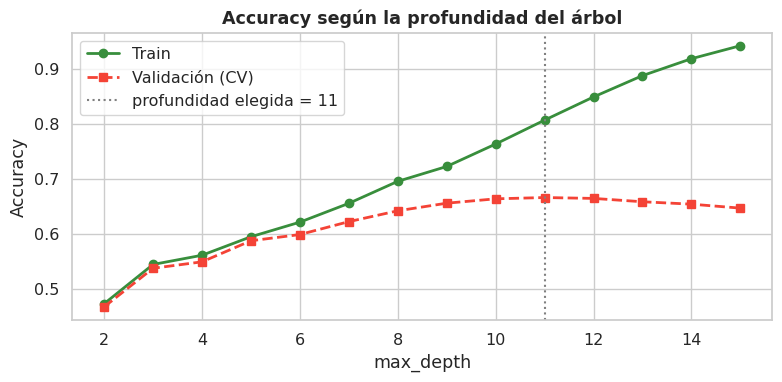

In [ ]:
profundidades = range(2, 16)
acc_train, acc_cv = [], []

for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=42)
    arbol.fit(X_train, y_train)
    acc_train.append(arbol.score(X_train, y_train))
    acc_cv.append(cross_val_score(arbol, X_train, y_train, cv=5).mean())

tabla_prof = pd.DataFrame({'max_depth': list(profundidades),
                           'Accuracy train': acc_train,
                           'Accuracy validación (CV)': acc_cv}).round(4)
display(tabla_prof)

mejor_prof = list(profundidades)[int(np.argmax(acc_cv))]
print(f"Profundidad con mejor accuracy de validación: {mejor_prof}")

plt.figure(figsize=(8, 4))
plt.plot(list(profundidades), acc_train, 'o-', label='Train', color='#388E3C', lw=2)
plt.plot(list(profundidades), acc_cv, 's--', label='Validación (CV)', color='#F44336', lw=2)
plt.axvline(mejor_prof, color='gray', linestyle=':', label=f'profundidad elegida = {mejor_prof}')
plt.title('Accuracy según la profundidad del árbol', fontweight='bold')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

**Observación:** con profundidades bajas el árbol es muy simple y los dos accuracy son bajos. Al aumentar la profundidad, el accuracy de **train sigue subiendo** (el árbol memoriza), pero el de **validación** sube hasta un máximo y después **empieza a bajar**. Elegimos la profundidad donde la validación es máxima, no donde el train es máximo.

In [ ]:
dt = DecisionTreeClassifier(max_depth=mejor_prof, random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

acc_dt_train = dt.score(X_train, y_train)
acc_dt_test = accuracy_score(y_test, dt_pred)

print(f"Accuracy en train: {acc_dt_train:.4f}")
print(f"Accuracy en test:  {acc_dt_test:.4f}")
print()
print(classification_report(y_test, dt_pred, target_names=le.classes_))

Accuracy en train: 0.8070
Accuracy en test:  0.6753

              precision    recall  f1-score   support

           A       0.67      0.79      0.72       669
           B       0.52      0.60      0.56       668
           C       0.68      0.55      0.61       670
           D       0.89      0.76      0.82       669

    accuracy                           0.68      2676
   macro avg       0.69      0.68      0.68      2676
weighted avg       0.69      0.68      0.68      2676



### Visualización del árbol y variables importantes

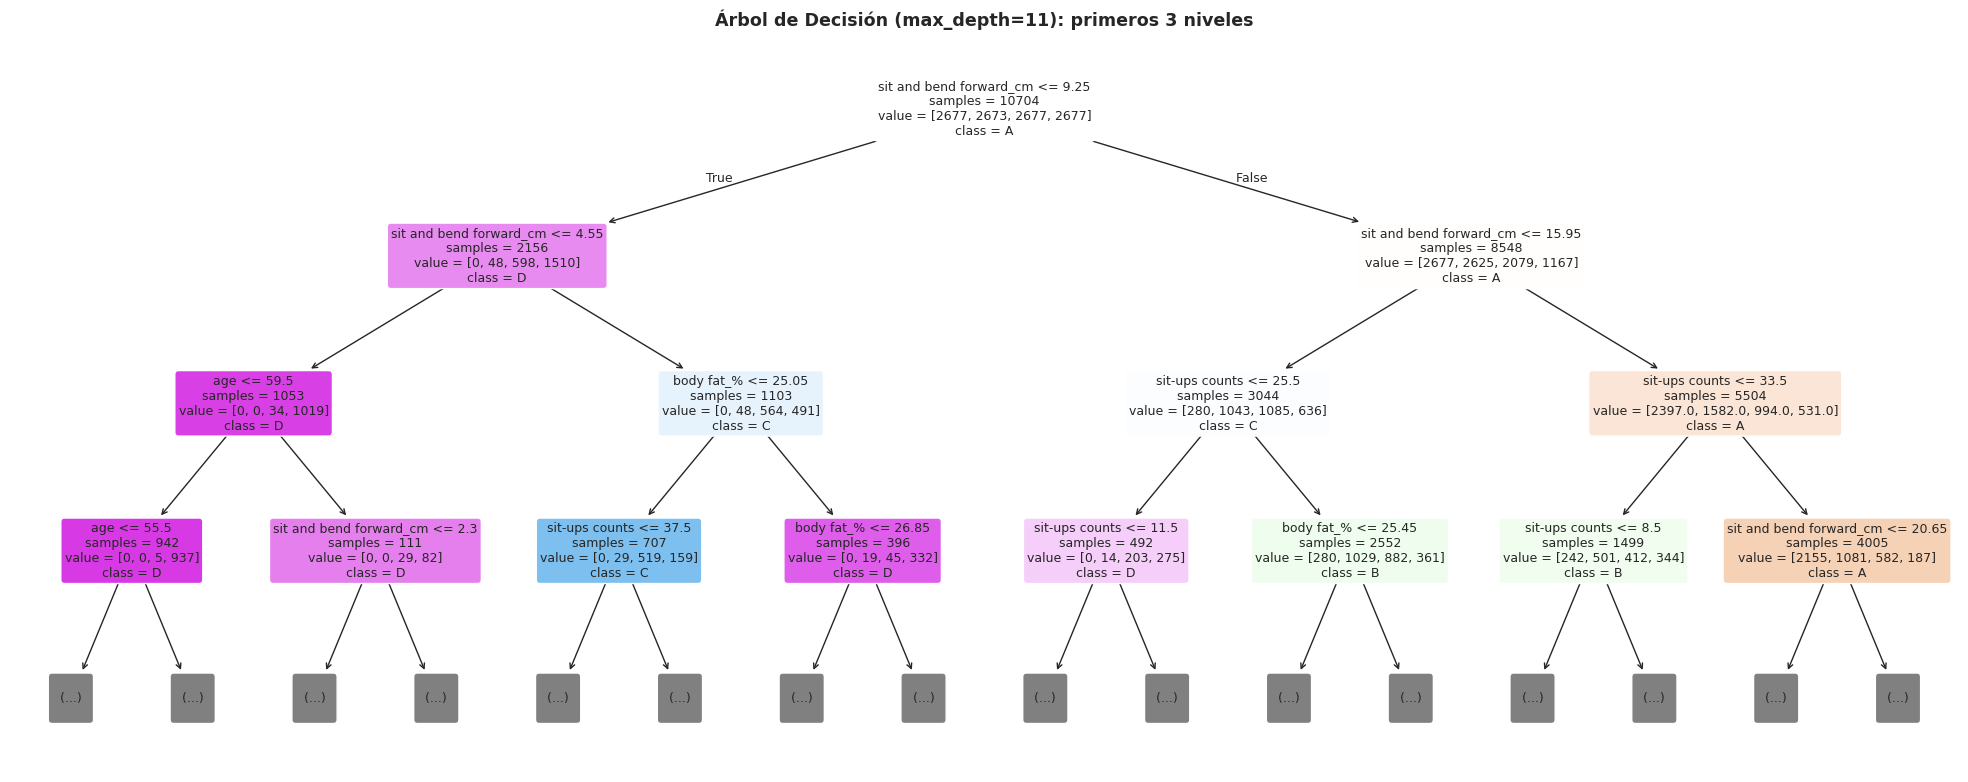

In [ ]:
# Se muestran solo los primeros 3 niveles para que se pueda leer
plt.figure(figsize=(20, 8))
plot_tree(dt, max_depth=3, feature_names=list(X.columns), class_names=list(le.classes_),
          filled=True, rounded=True, fontsize=9, impurity=False)
plt.title(f'Árbol de Decisión (max_depth={mejor_prof}): primeros 3 niveles', fontweight='bold')
plt.tight_layout()
plt.show()

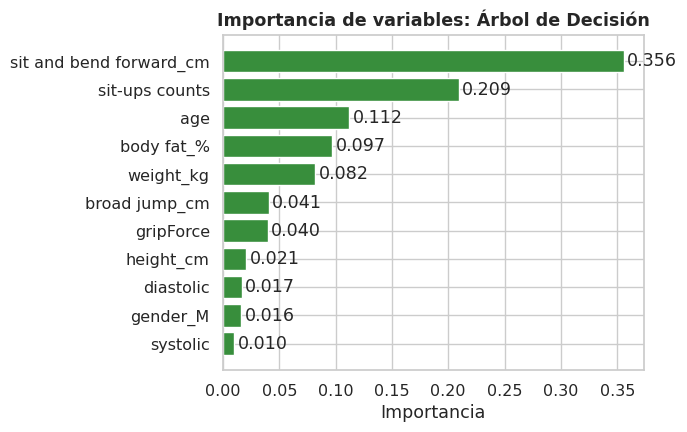

In [ ]:
importancia = pd.Series(dt.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importancia.index, importancia.values, color='#388E3C', edgecolor='white')
for i, v in enumerate(importancia.values):
    plt.text(v + 0.003, i, f'{v:.3f}', va='center')
plt.title('Importancia de variables: Árbol de Decisión', fontweight='bold')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

Las variables más importantes para el árbol son la **flexibilidad** (sit and bend forward_cm) y los **abdominales** (sit-ups counts), seguidas por la edad y el porcentaje de grasa. La primera pregunta del árbol usa la flexibilidad. Esto coincide con lo que vimos en el EDA.

## Evaluación y comparación de modelos

### Matrices de confusión
Las filas son la clase real y las columnas la predicción. Lo ideal es que los números grandes queden en la diagonal.

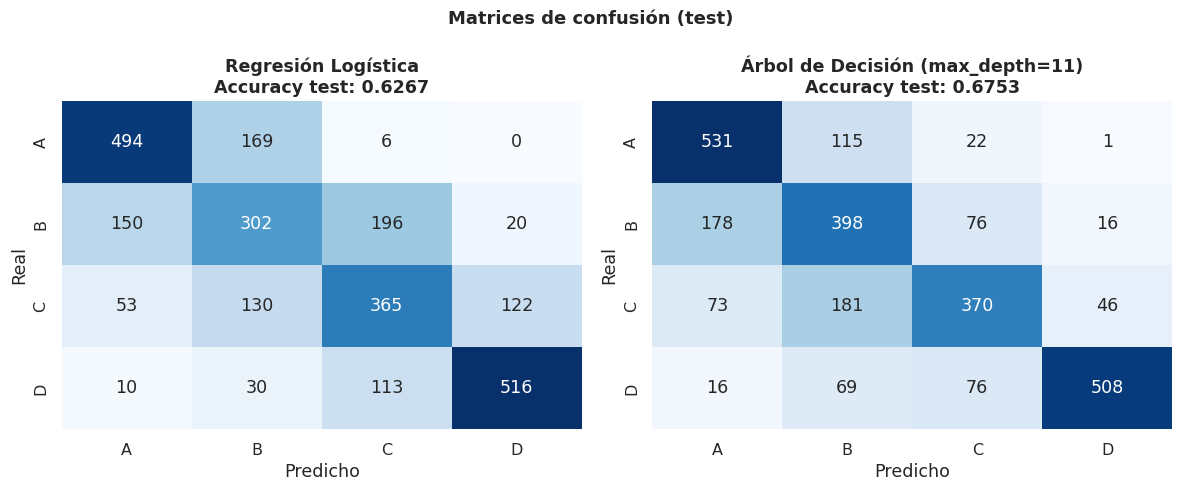

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, titulo in zip(axes, [lr_pred, dt_pred],
                            ['Regresión Logística', f'Árbol de Decisión (max_depth={mejor_prof})']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(f'{titulo}\nAccuracy test: {accuracy_score(y_test, pred):.4f}', fontweight='bold')
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
fig.suptitle('Matrices de confusión (test)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Los dos modelos aciertan más en las clases de los extremos (A y D) y se confunden más en las del medio (B y C). La mayoría de los errores son entre **clases vecinas** (A con B, B con C, C con D), lo cual tiene sentido porque el rendimiento es una escala: es difícil separar niveles contiguos.

### Validación cruzada (5 pliegues)
Para ver si el resultado depende de cómo se dividieron los datos, repetimos la evaluación en 5 particiones del entrenamiento.

In [ ]:
cv_lr = cross_val_score(lr, X_train_sc, y_train, cv=5)
cv_dt = cross_val_score(dt, X_train, y_train, cv=5)

print("Validación cruzada (5 pliegues):")
print(f"  Regresión Logística: {cv_lr.round(4)} → Media: {cv_lr.mean():.4f} ± {cv_lr.std():.4f}")
print(f"  Árbol de Decisión:   {cv_dt.round(4)} → Media: {cv_dt.mean():.4f} ± {cv_dt.std():.4f}")

Validación cruzada (5 pliegues):
  Regresión Logística: [0.6175 0.6179 0.6109 0.6282 0.6107] → Media: 0.6171 ± 0.0064
  Árbol de Decisión:   [0.6763 0.6478 0.6866 0.6628 0.6579] → Media: 0.6663 ± 0.0137


### Tabla resumen comparativa

In [ ]:
resumen = pd.DataFrame({
    'Modelo': ['Regresión Logística', f'Árbol de Decisión (max_depth={mejor_prof})'],
    'Accuracy train': [acc_lr_train, acc_dt_train],
    'Accuracy test': [acc_lr_test, acc_dt_test],
    'CV media': [cv_lr.mean(), cv_dt.mean()],
    'CV desvío': [cv_lr.std(), cv_dt.std()],
    'Diferencia train − test': [acc_lr_train - acc_lr_test, acc_dt_train - acc_dt_test],
}).set_index('Modelo').round(4)
resumen

print("Reporte Regresión Logística:")
print(classification_report(y_test, lr_pred))

print("Reporte Árbol de Decisión:")
print(classification_report(y_test, dt_pred))

Reporte Regresión Logística:
              precision    recall  f1-score   support

           0       0.70      0.74      0.72       669
           1       0.48      0.45      0.46       668
           2       0.54      0.54      0.54       670
           3       0.78      0.77      0.78       669

    accuracy                           0.63      2676
   macro avg       0.62      0.63      0.63      2676
weighted avg       0.62      0.63      0.63      2676

Reporte Árbol de Decisión:
              precision    recall  f1-score   support

           0       0.67      0.79      0.72       669
           1       0.52      0.60      0.56       668
           2       0.68      0.55      0.61       670
           3       0.89      0.76      0.82       669

    accuracy                           0.68      2676
   macro avg       0.69      0.68      0.68      2676
weighted avg       0.69      0.68      0.68      2676



## Conclusión

### ¿Cuál modelo aborda mejor el problema?
**El Árbol de Decisión** es el modelo que mejor clasifica el nivel de rendimiento físico en este dataset.

| Criterio | Regresión Logística | Árbol de Decisión |
|---|---|---|
| Accuracy test | 62.67 % | **67.53 %** |
| Validación cruzada | 61.71 % ± 0.64 | **66.63 %** ± 1.37 |
| Accuracy train | 61.82 % | 80.70 % |
| Diferencia train − test | −0.85 puntos | +13.17 puntos |
| Tipo de relación | Lineal | No lineal |
| Interpretabilidad | Coeficientes por variable | Reglas y variables importantes |
| Requiere normalización | Sí | No |

El árbol supera a la regresión logística en test y también en validación cruzada (alrededor de 5 puntos más en ambos), por lo que la ventaja no depende de una división particular de los datos. Una explicación probable es que las clases **no se separan bien con fronteras lineales**: el árbol puede combinar preguntas sobre varias variables, algo que un modelo lineal no puede hacer. Además mejora el desempeño en las clases difíciles (B y C).

### Sobreajuste
En el árbol hay **algo de sobreajuste**: acierta mucho más en train (80.70 %) que en test (67.53 %). Aun así su accuracy en test sigue siendo mejor que el de la regresión logística, y la profundidad se eligió con validación cruzada justamente para equilibrar ese efecto. La regresión logística, en cambio, tiene train y test casi iguales (no sobreajusta), pero su accuracy es más bajo: es un modelo demasiado simple para este problema.
